## Machine Learning CA1

**Programme:** Higher Diploma in Science in Data Analytics for Business - CCT College Dublin

**Module:** Machine Learning    
**Lecturer:** Dr. Muhammad Iqbal      
**Assessment:** Individual CA1  
**Dataset:**  `student-mat.csv` | `student.txt`

**Dataset link:** https://archive.ics.uci.edu/dataset/320/student+performance?utm_source=chatgpt.com

**GitHub link** https://github.com/sba23349-spec/CA1_MachineLearning_sba23349.git

**Deadline** 20/11/2026

## Project Overview:

This dataset contains information about students' academic
performance in Mathematics.

The objective is to predict whether a student will pass
or fail using classification models.


# 1 - Dataset Loading and Initial Inspection

The first step is to load the student dataset and inspect its structure before performing data cleaning and exploratory analysis.

In [1]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Loading the dataset
df_original = pd.read_csv('student-mat.csv', sep=';')

df_original.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


The first five rows were displayed to provide an initial overview of the dataset and verify that the CSV file was imported correctly.

## 1.1 - Dataset Dimensions

The number of rows and columns in the dataset is examined below.

In [5]:
print("Number of rows:", df_original.shape[0])
print("Number of columns:", df_original.shape[1])

Number of rows: 395
Number of columns: 33


The original dataset contains **395 observations and 33 columns**.

## 1.2 - Inspecting Data Types

The structure and data types of the variables were examined to identify whether any variables required conversion before the statistical analysis.

In [6]:
df_original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

## 1.3 - First Look at Missing Values

Missing values were checked to assess the completeness of the dataset before conducting the statistical analysis.

In [7]:
null_count = df_original.isnull().sum()

print("Number of null values:\n", null_count)

Number of null values:
 school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


No missing values were identified in this dataset.

## 1.4 - Checking for Duplicate Observations

The dataset was checked for duplicate rows to identify potentially repeated student records.

In [8]:
duplicate_count = df_original.duplicated().sum()

print("Number of duplicated rows:", duplicate_count)

Number of duplicated rows: 0


In [9]:
for column in df_original.columns:
    print(f"\n--- {column} ---")
    print(df_original[column].value_counts(dropna=False))


--- school ---
school
GP    349
MS     46
Name: count, dtype: int64

--- sex ---
sex
F    208
M    187
Name: count, dtype: int64

--- age ---
age
16    104
17     98
18     82
15     82
19     24
20      3
22      1
21      1
Name: count, dtype: int64

--- address ---
address
U    307
R     88
Name: count, dtype: int64

--- famsize ---
famsize
GT3    281
LE3    114
Name: count, dtype: int64

--- Pstatus ---
Pstatus
T    354
A     41
Name: count, dtype: int64

--- Medu ---
Medu
4    131
2    103
3     99
1     59
0      3
Name: count, dtype: int64

--- Fedu ---
Fedu
2    115
3    100
4     96
1     82
0      2
Name: count, dtype: int64

--- Mjob ---
Mjob
other       141
services    103
at_home      59
teacher      58
health       34
Name: count, dtype: int64

--- Fjob ---
Fjob
other       217
services    111
teacher      29
at_home      20
health       18
Name: count, dtype: int64

--- reason ---
reason
course        145
home          109
reputation    105
other          36
Name: count

In [10]:
dictionary_dataset = open("student.txt")
print(dictionary_dataset.read())

# Attributes for both student-mat.csv (Math course) and student-por.csv (Portuguese language course) datasets:
1 school - student's school (binary: "GP" - Gabriel Pereira or "MS" - Mousinho da Silveira)
2 sex - student's sex (binary: "F" - female or "M" - male)
3 age - student's age (numeric: from 15 to 22)
4 address - student's home address type (binary: "U" - urban or "R" - rural)
5 famsize - family size (binary: "LE3" - less or equal to 3 or "GT3" - greater than 3)
6 Pstatus - parent's cohabitation status (binary: "T" - living together or "A" - apart)
7 Medu - mother's education (numeric: 0 - none,  1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)
8 Fedu - father's education (numeric: 0 - none,  1 - primary education (4th grade), 2 – 5th to 9th grade, 3 – secondary education or 4 – higher education)
9 Mjob - mother's job (nominal: "teacher", "health" care related, civil "services" (e.g. administrative or police), "at_home" or 

In [28]:
df_original['G3'].value_counts().sort_index()

G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64

## 2. Exploratory Data Analysis (EDA)

The goal of this section is to explore the dataset and identify possible relationships between students' characteristics and their final Mathematics grades (G3).

The analysis focuses on study time, previous failures, absences and other factors that may be associated with academic performance.

Visualisations and summary statistics will be used to understand the distribution of the data and identify patterns before building the classification models.


### 2.1 Distribution of Final Grades (G3)

This analysis examines the distribution of students' final Mathematics grades to understand how their performance varies across the dataset.


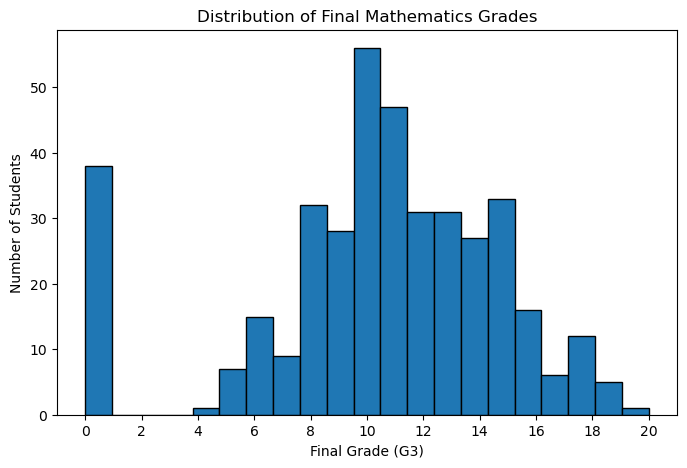

In [30]:
plt.figure(figsize=(8, 5))
plt.hist(df_original['G3'], bins=21, edgecolor='black')

plt.title('Distribution of Final Mathematics Grades')
plt.xlabel('Final Grade (G3)')
plt.ylabel('Number of Students')
plt.xticks(range(0, 21, 2))
plt.show()

The histogram shows that most final Mathematics grades (G3) are concentrated between 8 and 15. The most frequent grade is 10, while 38 students (approximately 9.6% of the dataset) received a final grade of zero. As grade 10 is the minimum passing grade, this distribution helps us understand how students are divided into Pass and Fail groups.

In [29]:
df_original.groupby('studytime')['G3'].mean()

studytime
1    10.047619
2    10.171717
3    11.400000
4    11.259259
Name: G3, dtype: float64

The results show that students who spend more time studying tend to have slightly higher average final grades. Students in study time category 3 (5 to 10 hours per week) had the highest average grade of 11.40. Students in study time category 4 (more than 10 hours per week) had a slightly lower average of 11.26 compared to category 3, suggesting that spending more time studying does not necessarily lead to higher grades. 

([<matplotlib.axis.XTick at 0x1524cf610>,
 [Text(0, 0, '<2h'),
  Text(1, 0, '2-5h'),
  Text(2, 0, '5-10h'),
  Text(3, 0, '>10h')])

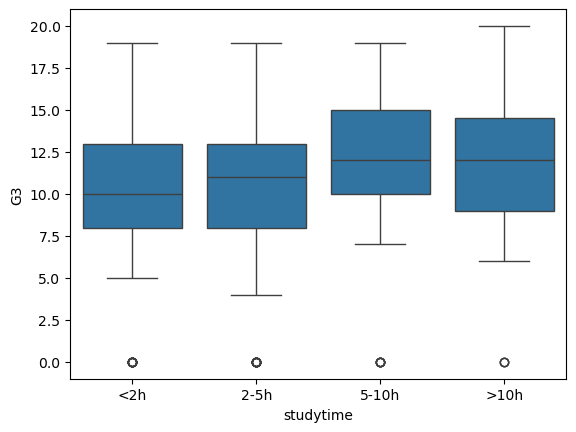

In [21]:
sns.boxplot(data=df_original, x='studytime', y='G3')
plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=['<2h', '2-5h', '5-10h', '>10h']
)

The boxplot shows that the median grades are slightly higher for students who spend more time studying. However, the distributions overlap, showing that students from different study time categories can achieve similar grades.

In [32]:
df_original['studytime'].value_counts(normalize=True).sort_index().mul(100).round(2)

studytime
1    26.58
2    50.13
3    16.46
4     6.84
Name: proportion, dtype: float64

Most students (50.1%) belong to study time category 2, while only 6.8% belong to category 4. As category 4 has fewer students, its average grade should be interpreted with caution.

### 2.3 Previous Failures and Final Grade

This analysis examines the relationship between students' previous academic failures and their final Mathematics grades.


In [33]:
df_original['failures'].value_counts(normalize=True).sort_index().mul(100).round(2)

failures
0    78.99
1    12.66
2     4.30
3     4.05
Name: proportion, dtype: float64

The results show that most students (79%) had no previous class failures. Only a small percentage of students had two previous class failures (4.30%), while 4.05% had three previous class failures.

In [34]:
df_original.groupby('failures')['G3'].mean().round(2)

failures
0    11.25
1     8.12
2     6.24
3     5.69
Name: G3, dtype: float64

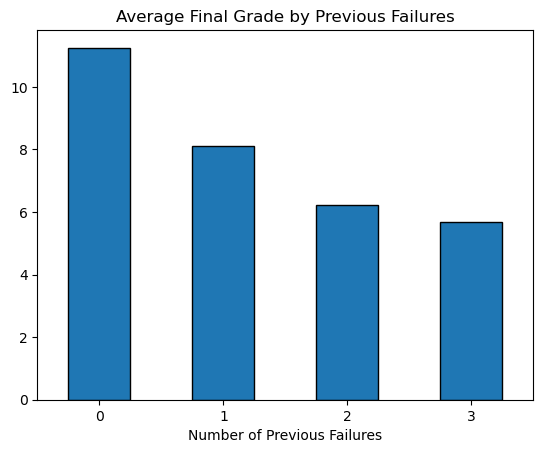

In [36]:
mean_grades = df_original.groupby('failures')['G3'].mean()

mean_grades.plot(kind='bar', edgecolor='black')

plt.title('Average Final Grade by Previous Failures')
plt.xlabel('Number of Previous Failures')
plt.xticks(rotation=0)
plt.show()

The average final grade decreases as the number of previous class failures increases, showing that students who had no previous class failures had the highest average grade in G3 (11.25), while those who had three previous class failures had a lower average grade (5.69). This suggests that previous class failures could be a useful feature for predicting whether a student will pass or fail Mathematics.

### 2.4 Absences and Final Grade

This analysis explores the relationship between the number of school absences and students' final Mathematics grades (G3).

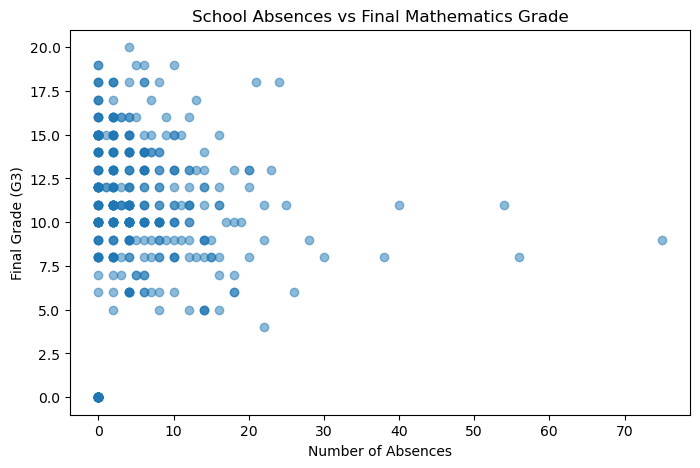

In [38]:
plt.figure(figsize=(8, 5))

plt.scatter(df_original['absences'], df_original['G3'], alpha=0.5)

plt.title('School Absences vs Final Mathematics Grade')
plt.xlabel('Number of Absences')
plt.ylabel('Final Grade (G3)')

plt.show()

The scatterplot shows that most students had between 0 and 20 absences. However, among students who had fewer absences, we can find practically the entire range of grades, from 0 to 20. There are also some students with a high number of absences, including one with more than 70 absences who still achieved a grade close to 9. This shows that we cannot identify a strong negative relationship based only on this plot.

In [39]:
df_original['absences'].corr(df_original['G3'])

np.float64(0.03424731615006931)

The Pearson correlation between absences and G3 was 0.0342, which is very close to zero. This indicates that there is almost no linear relationship between the number of absences and students' final Mathematics grades.

## 3. Feature Engineering and Data Preprocessing

In this section, the dataset will be prepared for the classification models. A new target variable, Pass_Fail, will be created using the final Mathematics grade (G3). Students with a grade of 10 or higher will be classified as Pass (1), while students with a grade below 10 will be classified as Fail (0).

In [40]:
df = df_original.copy()

In [41]:
df['Pass_Fail'] = (df['G3'] >= 10).astype(int)

In [42]:
df[['G3', 'Pass_Fail']].head(10)

,G3,Pass_Fail
0,6,0
1,6,0
2,10,1
3,15,1
4,10,1
5,15,1
6,11,1
7,6,0
8,19,1
9,15,1


In [43]:
df['Pass_Fail'].value_counts()

Pass_Fail
1    265
0    130
Name: count, dtype: int64

## 4. Data Preprocessing

In this section, the dataset will be prepared for training the classification models. The predictor variables (X) and target variable (y) will be separated, and categorical variables will be encoded so they can be used by the machine learning algorithms.

### 4.1 Feature Selection

The aim is to predict whether a student will pass or fail Mathematics after the first grading period. G1 will be included as a predictor, while G2 and G3 will be excluded because these grades would not yet be available at the time of prediction. G3 is also used to create the target variable, so including it would cause data leakage.

In [46]:
X = df.drop(columns=['G2', 'G3', 'Pass_Fail', 'absences'])
y = df['Pass_Fail']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (395, 30)
y shape: (395,)


### 4.2 Train-Test Split

The dataset will be divided into training and testing sets to evaluate how well the classification models perform on unseen data. Stratification will be used to maintain a similar proportion of Pass and Fail students in both sets.

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (296, 30)
Testing set: (99, 30)


### 4.3 Categorical Encoding and Feature Scaling

The dataset contains both numerical and categorical variables. Before training the models, categorical variables need to be converted into numerical values.

Binary variables were converted into 0 and 1 using mapping. One-Hot Encoding was applied to nominal variables with multiple categories, such as Mjob, Fjob, reason and guardian.

The encoding was applied separately to the training and testing datasets, keeping the same feature columns in both sets.

Feature scaling will be applied during model training.

In [79]:
categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=['number']
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))

Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Numerical features: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'G1']

Number of categorical features: 17
Number of numerical features: 13


In [51]:
binary_features = [
    'school', 'sex', 'address', 'famsize', 'Pstatus',
    'schoolsup', 'famsup', 'paid', 'activities',
    'nursery', 'higher', 'internet', 'romantic'
]

nominal_features = [
    'Mjob', 'Fjob', 'reason', 'guardian'
]

In [52]:
X_train_mapped = X_train.copy()
X_test_mapped = X_test.copy()

mapping = {
    'school': {'GP': 0, 'MS': 1},
    'sex': {'F': 0, 'M': 1},
    'address': {'U': 0, 'R': 1},
    'famsize': {'LE3': 0, 'GT3': 1},
    'Pstatus': {'T': 0, 'A': 1},
    'schoolsup': {'no': 0, 'yes': 1},
    'famsup': {'no': 0, 'yes': 1},
    'paid': {'no': 0, 'yes': 1},
    'activities': {'no': 0, 'yes': 1},
    'nursery': {'no': 0, 'yes': 1},
    'higher': {'no': 0, 'yes': 1},
    'internet': {'no': 0, 'yes': 1},
    'romantic': {'no': 0, 'yes': 1}
}

for col, values in mapping.items():
    X_train_mapped[col] = X_train_mapped[col].map(values)
    X_test_mapped[col] = X_test_mapped[col].map(values)

In [53]:
X_train_prepared = pd.get_dummies(
    X_train_mapped,
    columns=nominal_features,
    dtype=int
)

X_test_prepared = pd.get_dummies(
    X_test_mapped,
    columns=nominal_features,
    dtype=int
)

X_test_prepared = X_test_prepared.reindex(
    columns=X_train_prepared.columns,
    fill_value=0
)

In [54]:
print("Training:", X_train_prepared.shape)
print("Testing:", X_test_prepared.shape)

print("Missing values:", X_train_prepared.isnull().sum().sum())

Training: (296, 43)
Testing: (99, 43)
Missing values: 0


## 5. Model Development

Two classification models were selected to predict students' final Mathematics results: Logistic Regression and Random Forest.

The models will be trained and evaluated to compare their performance in predicting whether students will pass or fail.

### 5.1 Logistic Regression

Logistic Regression was selected as the first model because it is commonly used for binary classification problems.

StandardScaler will be used to standardise the features before training the model.

In [55]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_prepared)
X_test_scaled = scaler.transform(X_test_prepared)

In [56]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [57]:
from sklearn.metrics import accuracy_score

y_pred_lr = lr_model.predict(X_test_scaled)

accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", round(accuracy_lr, 4))

Logistic Regression Accuracy: 0.7475


In [66]:
# Predict on the test set
y_pred_lr = lr_model.predict(X_test_scaled)

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred_lr)

report = classification_report(
    y_test, y_pred_lr, output_dict=True
)

precision = report['weighted avg']['precision']
recall = report['weighted avg']['recall']
f1_score = report['weighted avg']['f1-score']

# Display results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1_score)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.7474747474747475
Precision: 0.7456467661691542
Recall: 0.7474747474747475
F1 Score: 0.7464815885868517

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.61      0.62        33
           1       0.81      0.82      0.81        66

    accuracy                           0.75        99
   macro avg       0.72      0.71      0.71        99
weighted avg       0.75      0.75      0.75        99



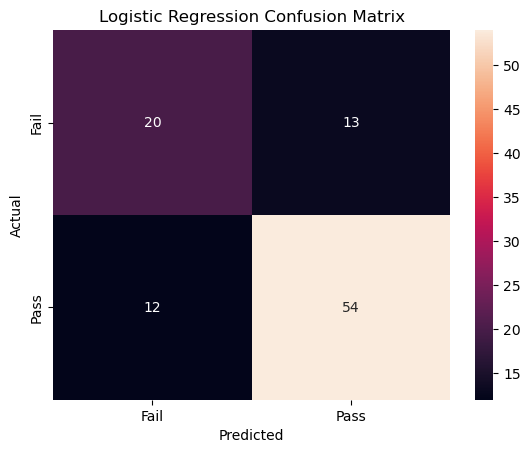

In [62]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Predict using Logistic Regression
y_predict = lr_model.predict(X_test_scaled)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=['Fail', 'Pass'],
            yticklabels=['Fail', 'Pass'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression Confusion Matrix')
plt.show()

The Logistic Regression model achieved an accuracy of 74.75% on the test set.

The model correctly classified 54 students who passed and 20 students who failed. However, 13 students who failed were incorrectly predicted to pass.

The recall for the Fail class was 61%, compared with 82% for the Pass class. This suggests that the model performs better at identifying students who pass than those who fail.

### 5.2 Random Forest

Random Forest was selected as the second classification model. It combines multiple decision trees to make predictions.

The model will be trained using the same training and testing sets as Logistic Regression to compare their performance.

In [64]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train_prepared, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [65]:
# Predict on the test set
y_pred_rf = rf_model.predict(X_test_prepared)

# Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred_rf)

report = classification_report(
    y_test, y_pred_rf, output_dict=True
)

precision = report['weighted avg']['precision']
recall = report['weighted avg']['recall']
f1_score = report['weighted avg']['f1-score']

# Display results
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1_score)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.8080808080808081
Precision: 0.804830917874396
Recall: 0.8080808080808081
F1 Score: 0.8056437389770723

Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.67      0.70        33
           1       0.84      0.88      0.86        66

    accuracy                           0.81        99
   macro avg       0.79      0.77      0.78        99
weighted avg       0.80      0.81      0.81        99



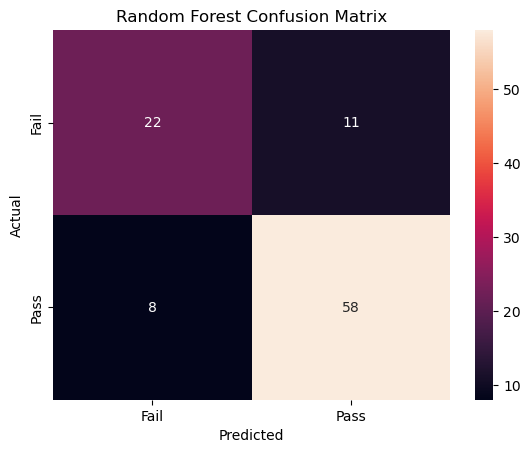

In [67]:
# Predict using Random Forest
y_predict = rf_model.predict(X_test_prepared)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=['Fail', 'Pass'],
            yticklabels=['Fail', 'Pass'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()

The Random Forest model achieved an accuracy of 80.81%, compared with 74.75% for Logistic Regression.

Random Forest also achieved higher Precision, Recall and F1-score. For students who failed, Recall increased from 61% to 67%, meaning that Random Forest identified more students at risk of failing.

These initial results suggest that Random Forest performs better on this test split. However, further evaluation using different test sizes and cross-validation is needed.

### 5.3 Comparison of Different Train-Test Splits

Three different test sizes (5%, 15% and 25%) were selected to evaluate the performance of Logistic Regression and Random Forest.

The same random state and stratified sampling were used to maintain a consistent class distribution. The models will be evaluated using Accuracy, Precision, Recall and F1-score.

In [68]:
test_sizes = [0.05, 0.15, 0.25]

classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

results = []

In [69]:
for test_size in test_sizes:

    # Split the dataset
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    # Apply mapping
    X_train_prepared = X_train.copy()
    X_test_prepared = X_test.copy()

    for col, values in mapping.items():
        X_train_prepared[col] = X_train_prepared[col].map(values)
        X_test_prepared[col] = X_test_prepared[col].map(values)

    # Apply One-Hot Encoding
    X_train_prepared = pd.get_dummies(
        X_train_prepared,
        columns=nominal_features,
        dtype=int
    )

    X_test_prepared = pd.get_dummies(
        X_test_prepared,
        columns=nominal_features,
        dtype=int
    )

    X_test_prepared = X_test_prepared.reindex(
        columns=X_train_prepared.columns,
        fill_value=0
    )

In [70]:
prepared_splits = {}

for test_size in test_sizes:

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    X_train_prepared = X_train.copy()
    X_test_prepared = X_test.copy()

    for col, values in mapping.items():
        X_train_prepared[col] = X_train_prepared[col].map(values)
        X_test_prepared[col] = X_test_prepared[col].map(values)

    X_train_prepared = pd.get_dummies(
        X_train_prepared, columns=nominal_features, dtype=int
    )

    X_test_prepared = pd.get_dummies(
        X_test_prepared, columns=nominal_features, dtype=int
    )

    X_test_prepared = X_test_prepared.reindex(
        columns=X_train_prepared.columns,
        fill_value=0
    )

    prepared_splits[test_size] = (
        X_train_prepared, X_test_prepared, y_train, y_test
    )

In [71]:
scaled_splits = {}

for test_size, data in prepared_splits.items():

    X_train_prepared, X_test_prepared, y_train, y_test = data

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_prepared)
    X_test_scaled = scaler.transform(X_test_prepared)

    scaled_splits[test_size] = (
        X_train_scaled, X_test_scaled
    )

In [72]:
results = []

for test_size in test_sizes:

    X_train_prepared, X_test_prepared, y_train, y_test = prepared_splits[test_size]
    X_train_scaled, X_test_scaled = scaled_splits[test_size]

    for name, classifier in classifiers.items():

        if name == "Logistic Regression":
            train_data = X_train_scaled
            test_data = X_test_scaled
        else:
            train_data = X_train_prepared
            test_data = X_test_prepared

        classifier.fit(train_data, y_train)
        y_pred = classifier.predict(test_data)

        accuracy = accuracy_score(y_test, y_pred)
        report = classification_report(
            y_test, y_pred, output_dict=True, zero_division=0
        )

        precision = report['weighted avg']['precision']
        recall = report['weighted avg']['recall']
        f1_score = report['weighted avg']['f1-score']

        results.append([
            test_size, name, accuracy, precision, recall, f1_score
        ])

In [73]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Test Size", "Model", "Accuracy",
        "Precision", "Recall", "F1 Score"
    ]
)

results_df.round(4)

,Test Size,Model,Accuracy,Precision,Recall,F1 Score
0,0.05,Logistic Regression,0.8000,0.8000,0.8000,0.8000
1,0.05,Random Forest,0.7500,0.7604,0.7500,0.7533
2,0.15,Logistic Regression,0.8000,0.8000,0.8000,0.8000
3,0.15,Random Forest,0.8000,0.8000,0.8000,0.8000
4,0.25,Logistic Regression,0.7475,0.7456,0.7475,0.7465
5,0.25,Random Forest,0.8081,0.8048,0.8081,0.8056


### Comparison of Test Sizes

The models were evaluated using three different test sizes: 5%, 15% and 25%.

Logistic Regression achieved 80% accuracy with the 5% and 15% test sizes, but decreased to 74.75% with 25%.

Random Forest achieved 75%, 80% and 80.81% accuracy, respectively.

The results show that model performance varies depending on the train-test split. Since the dataset contains only 395 students, smaller test sets may provide less reliable estimates of performance.

In [84]:
rf_cv_scores = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X_train_prepared,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Random Forest CV Scores:", [round(score, 4) for score in rf_cv_scores])
print("Mean CV Accuracy:", round(rf_cv_scores.mean(), 4))

Random Forest CV Scores: [np.float64(0.8), np.float64(0.8305), np.float64(0.7288), np.float64(0.8983), np.float64(0.8475)]
Mean CV Accuracy: 0.821


In [85]:
lr_cv_scores = cross_val_score(
    LogisticRegression(max_iter=1000, random_state=42),
    X_train_scaled,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Logistic Regression CV Scores:", [round(score, 4) for score in lr_cv_scores])
print("Mean CV Accuracy:", round(lr_cv_scores.mean(), 4))

Logistic Regression CV Scores: [np.float64(0.9), np.float64(0.8644), np.float64(0.7458), np.float64(0.8475), np.float64(0.7797)]
Mean CV Accuracy: 0.8275


### Cross-Validation Results

Five-fold cross-validation was used to evaluate both models.

Logistic Regression had an average accuracy of 82.75%, while Random Forest achieved 82.10%.

The results were very similar, with Logistic Regression performing slightly better.